# AVAX SHORT — thuận xu hướng: Bollinger dài hạn + RSI ngắn hạn, train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`, luật breakout `entry_mode = 0`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Ý tưởng:** Bollinger là chỉ báo **dài hạn** (`boll_window` 48–672 nến = 12 giờ → 7 ngày ở 15min), RSI là chỉ báo **ngắn hạn** (`rsi_window` 2–14). Khi giá phá ra khỏi dải và RSI ngắn hạn xác nhận lực, vào lệnh **thuận chiều** phá dải (bản đối xứng của `long|short_bollinger+RSI+fade`).

**Vào lệnh ở close của nến `i`:** `close[i-1] > lower[i] > close[i]` (đóng cửa vượt xuống dưới dải dưới) **và** `RSI[i] < rsi_threshold`.

**Rủi ro:** risk = `sl_multiplier × (upper[i] − entry)` ≈ `sl × độ rộng dải`; stop = entry + risk; TP = entry − `tp_sl_ratio` × risk; `tp_sl_ratio = 0` là **không chốt lời** (chỉ stop hoặc hết thời gian giữ). Timeout `max_holding_bars` nến (cột của grid; `MAX_HOLDING_BARS` chỉ dùng khi grid không có cột này); phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh mỗi 8 giờ (`FEE_BARS = None` ⇒ 32 ở 15min); một lệnh mỗi lúc.

**Bộ lọc độ rộng dải** (`band_ratio_max`, 0 = tắt): tín hiệu chỉ được vào lệnh khi độ rộng dải lúc đó `(upper − lower) / close` ≤ `band_ratio_max` × **trung vị** độ rộng của 30 ngày trước đó — tức là phá xuống từ một dải đang hẹp so với gần đây. 10 ngày đầu của dữ liệu chưa đủ để tính nên không có lệnh. Với trial 11117 (2021–2026), `band_ratio_max` 0.8–1.5 làm **mọi năm đều có lãi kể cả 2021**, đổi lại tổng R 2022–2026 thấp hơn (45–56R so với 67R). Ý tưởng bộ lọc này được tìm ra khi xem dữ liệu 2021–2026, nên kết quả trên các năm đó không còn là ngoài mẫu.

**Số lệnh mỗi năm** (`min_trades_per_year`, cột kết quả): số lệnh đóng trong **năm ít lệnh nhất**, mỗi năm quy ra cả năm (năm phủ dưới nửa năm bị bỏ qua nếu có năm phủ nhiều hơn). Đây là **bộ lọc xếp hạng** (`MIN_TRADES_PER_YEAR`), không phải tham số chiến lược — nó không đổi lệnh nào, chỉ loại các bộ có năm gần như không giao dịch.

**Wilson lower bound** (`reference/Wilson_Lower_Bound_RR_Strategy_VI.docx`): lệnh **thắng** là lệnh có R ròng (sau phí) > 0. Cột kết quả:
`number_of_win`, `win_rate` = W/N, `avg_win_r` (R ròng trung bình của lệnh thắng), `avg_loss_r` (|R ròng| trung bình của lệnh còn lại), `wilson_p_lower` = cận dưới Wilson **một phía** của tỷ lệ thắng ở mức `WILSON_CONFIDENCE` (0.95 ⇒ z = 1.645), và

`wilson_fitness = p_L × avg_win_r − (1 − p_L) × avg_loss_r` (R/lệnh, sau phí).

Khi payoff cố định +kR / −1R và phí cố định cR, công thức này đúng bằng `(k + 1)·p_L − 1 − c` của tài liệu. Có timeout (và `tp_sl_ratio = 0`) thì payoff biến thiên: Wilson chỉ bao độ bất định của **tỷ lệ thắng**, không bao độ lớn lãi/lỗ (mục 8 của tài liệu) — nên xem thêm tỷ lệ timeout ở ô backtest. Wilson cũng không đo drawdown; kết hợp với `r2`, `max_dd` nếu cần.

**Xếp hạng theo vùng lân cận** (`NEIGHBOUR_RANKING = True`): `score_own` là score của chính bộ tham số; `score` là **trung vị** `score_own` của mọi bộ lệch ≤ `NEIGHBOUR_RADIUS` nấc ở từng tham số trong danh sách `SEARCH_SPACES` (gồm chính nó; ví dụ quanh `sl = 1.2` là 1.1, 1.2, 1.3). Bộ không đủ `MIN_TRADES` / `MIN_TRADES_PER_YEAR` không được tính làm lân cận; bộ có dưới nửa số lân cận hợp lệ bị bỏ. Một bộ chỉ đứng đầu khi **cả vùng quanh nó** đều tốt, nên đỉnh nhọn nhờ may mắn bị đẩy xuống. Khi thử train → test trên 25 coin × 2 cách chia, `SCORE_FORMULA = "performance"` + lân cận là cách chọn duy nhất hơn ngẫu nhiên ở cả hai cách chia (phân vị test trung bình 0.61; ngẫu nhiên = 0.5) — hơn ít, không phải bảo đảm. "±1 nấc" phụ thuộc cách đặt bước của danh sách: bước không đều (ví dụ `boll_window` 40 → 45 so với 150 → 200) thì vùng lân cận cũng không đều. `walk_forward_multi_asset.py` chỉ đọc `SCORE_FORMULA`, chưa dùng xếp hạng lân cận.

**ID của trial** là số thứ tự trong grid: đổi `SEARCH_SPACES` là ID đổi theo. Ô backtest có `TRIAL_PARAMS` để tìm theo tham số (ví dụ trial 11117 cũ).

Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_multi_asset.py --folder short_bollinger+RSI+trend` (đọc grid và `SCORE_FORMULA` từ ô Cấu hình này).

In [16]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2021-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-01-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = "../data_5m/avaxusdt_futures_5min.csv"                     # None = reference/data/avaxusdt_futures_5min.csv
#DATA_CSV = None
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

#SCORE_FORMULA = "performance*r2**5"
#SCORE_FORMULA = "performance"      # cùng NEIGHBOUR_RANKING = True: cách chọn tốt nhất khi thử 25 coin × 2 cách chia
#SCORE_FORMULA = "r_martin_monthly"
#SCORE_FORMULA = "r_sharpe_monthly"
#SCORE_FORMULA = "performance/number_of_trade*r2**5"
SCORE_FORMULA = "performance*r2**5"
#SCORE_FORMULA = "performance/number_of_trade"
#SCORE_FORMULA = "wilson_fitness"                    # R/lệnh thận trọng theo cận dưới Wilson của tỷ lệ thắng
#SCORE_FORMULA = "wilson_fitness*number_of_trade"   # tổng R thận trọng (ưu tiên bộ nhiều lệnh hơn)
#SCORE_FORMULA = "wilson_fitness*r2**5"             # thêm độ thẳng của equity
WILSON_CONFIDENCE = 0.98            # cận dưới một phía: 0.90 (z=1.282), 0.95 (z=1.645), 0.99 (z=2.326)
NEIGHBOUR_RANKING = False           # True = xếp hạng theo trung vị score của vùng lân cận (vùng phẳng, không phải đỉnh nhọn)
NEIGHBOUR_RADIUS = 1               # số nấc lệch tối đa của mỗi tham số trong danh sách SEARCH_SPACES
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
# tp_sl_ratio = 0 nghĩa là không chốt lời (chỉ stop hoặc hết thời gian giữ).
# max_holding_bars: số nến tối đa giữ lệnh (timeout), mỗi bộ một giá trị.
# band_ratio_max: chỉ vào lệnh khi độ rộng dải ≤ band_ratio_max × trung vị độ rộng 30 ngày trước (0 = tắt bộ lọc).
SEARCH_SPACES = {
    "boll_window": [5, 6, 8, 10, 14, 20, 25,30, 40, 60, 80, 100, 200, 400, 600],
    "boll_window_dev": [1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3],
    #"rsi_window": [5, 7, 9, 14, 20, 30],
    #"rsi_threshold": [5, 10, 15, 20, 25, 30, 35, 40],
    "rsi_window": [14],
    "rsi_threshold": [100],
    "sl_multiplier": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0],
    "tp_sl_ratio": [1.1],
    "max_holding_bars": [192, 240, 288, 336, 384],
    "band_ratio_max": [0.5, 0.6, 0.7, 0.8, 1.0, 1.5],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # chỉ dùng khi SEARCH_SPACES không có max_holding_bars
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (32 ở 15min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 100                     # bảng xếp hạng chỉ giữ bộ có ít nhất số lệnh này (cũng là ngưỡng để tính làm lân cận)
MIN_TRADES_PER_YEAR = 20           # và ít nhất số lệnh này trong năm ít lệnh nhất (quy ra cả năm; 0 = không lọc)
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [17]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "short_bollinger+RSI+trend"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

# Bỏ engine đã cache trong kernel, để chạy lại ô này là nạp bản engine mới nhất (không cần restart kernel)
sys.modules.pop("multi_position_engine", None)
spec = importlib.util.spec_from_file_location("avax_short_bollinger_RSI_trend", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến")

CSV: C:\Users\Legion\Desktop\TradingProject\reference\data_5m\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+trend\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến


In [18]:
# Đọc dữ liệu, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 140,352 nến; 2021-01-01 00:00:00 → 2025-01-01 23:45:00
Grid: 50,400 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,max_holding_bars,band_ratio_max
0,5,1.7,14,100,0.5,1.1,192,0.5
1,5,1.7,14,100,0.5,1.1,192,0.6
2,5,1.7,14,100,0.5,1.1,192,0.7
3,5,1.7,14,100,0.5,1.1,192,0.8
4,5,1.7,14,100,0.5,1.1,192,1.0


In [19]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")

c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Thời gian: {'indicators_and_transfer_s': 29.403204500005813, 'holding_fee_bars': 32.0, 'total_gpu_s': 32.49639060001937}
Đã tính 50,400 bộ tham số


In [20]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA, WILSON_CONFIDENCE, NEIGHBOUR_* hoặc MIN_TRADES*
result = strategy.add_wilson_columns(result, WILSON_CONFIDENCE)
result = strategy.score_result(result, SCORE_FORMULA)
result["score_own"] = result["score"]  # score của chính bộ tham số
# bộ đủ điều kiện xếp hạng: đủ MIN_TRADES lệnh tổng và đủ MIN_TRADES_PER_YEAR lệnh ở năm ít lệnh nhất
eligible = (result["number_of_trade"] >= MIN_TRADES) & (result["min_trades_per_year"] >= MIN_TRADES_PER_YEAR) #& (result["r2"]>0.96)   #  & (result["win_rate"]<0.57)
if NEIGHBOUR_RANKING:
    # score = trung vị score_own của mọi bộ lệch ≤ NEIGHBOUR_RADIUS nấc ở từng tham số (gồm chính nó); bộ không đủ
    # điều kiện không được tính làm lân cận, và bộ có dưới nửa số lân cận hợp lệ bị bỏ (score = NaN)
    result["score"] = strategy.neighbour_score(result.assign(score_own=result["score_own"].where(eligible)), space,
                                               "score_own", radius=NEIGHBOUR_RADIUS)
print("Score:", SCORE_FORMULA, f"| Wilson một phía {WILSON_CONFIDENCE:.0%}",
      f"| xếp hạng theo trung vị lân cận ±{NEIGHBOUR_RADIUS} nấc" if NEIGHBOUR_RANKING else "| xếp hạng theo score riêng",
      f"| đủ điều kiện: {int(eligible.sum()):,}/{len(result):,} bộ")

Score: performance*r2**5 | Wilson một phía 98% | xếp hạng theo score riêng | đủ điều kiện: 41,421/50,400 bộ


In [21]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME)

In [22]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[eligible & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ, ≥ {MIN_TRADES} lệnh và ≥ {MIN_TRADES_PER_YEAR} lệnh/năm: {len(ranked):,}/{len(result):,}")
display(ranked.head(100))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI+trend\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ, ≥ 100 lệnh và ≥ 20 lệnh/năm: 41,421/50,400


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,max_holding_bars,band_ratio_max,performance,max_dd,...,number_of_trade,max_concurrent,skipped_entries,number_of_win,win_rate,wilson_p_lower,wilson_fitness,score,score_formula,score_own
31241,60,1.9,14,100,0.6,1.1,240,1.5,112.643959,17.240000,...,1171,1,2056,647,0.552519,0.522542,0.033632,89.009468,performance*r2**5,89.009468
31253,60,1.9,14,100,0.6,1.1,336,1.5,109.927208,17.370001,...,1155,1,2072,635,0.549784,0.519591,0.031847,88.678689,performance*r2**5,88.678689
31259,60,1.9,14,100,0.6,1.1,384,1.5,108.848137,17.370001,...,1153,1,2074,633,0.549003,0.518782,0.030970,87.650579,performance*r2**5,87.650579
31247,60,1.9,14,100,0.6,1.1,288,1.5,108.864243,17.370001,...,1159,1,2068,636,0.548749,0.518607,0.030819,87.168567,performance*r2**5,87.168567
31235,60,1.9,14,100,0.6,1.1,192,1.5,110.455269,17.730000,...,1176,1,2051,645,0.548469,0.518546,0.031931,85.756930,performance*r2**5,85.756930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41774,200,2.0,14,100,0.5,1.1,288,0.7,70.183197,4.300000,...,223,1,389,145,0.650224,0.582400,0.172382,63.212810,performance*r2**5,63.212810
41780,200,2.0,14,100,0.5,1.1,336,0.7,70.183197,4.300000,...,223,1,389,145,0.650224,0.582400,0.172382,63.212810,performance*r2**5,63.212810
41786,200,2.0,14,100,0.5,1.1,384,0.7,70.183197,4.300000,...,223,1,389,145,0.650224,0.582400,0.172382,63.212810,performance*r2**5,63.212810
37492,100,1.8,14,100,0.6,1.1,336,1.0,78.902298,11.150000,...,674,1,1272,376,0.557864,0.518336,0.034172,62.918445,performance*r2**5,62.918445


In [23]:
# So sánh theo từng chiều tham số: trung vị toàn grid (ít nhiễu hơn bộ "tốt nhất")
view = result.assign(tp_kind=np.where(result["tp_sl_ratio"] > 0, "R cố định", "không TP"))


def family(frame):
    return pd.Series({
        "số bộ": len(frame),
        "lệnh (trung vị)": frame["number_of_trade"].median(),
        f"% bộ ≥ {MIN_TRADES} lệnh": (frame["number_of_trade"] >= MIN_TRADES).mean(),
        "lệnh/năm ít nhất (trung vị)": frame["min_trades_per_year"].median(),
        "R/tháng (trung vị)": frame["r_per_month"].median(),
        "% bộ có lãi": (frame["performance"] > 0).mean(),
        "max DD (trung vị)": frame["max_dd"].median(),
        "win rate (trung vị)": frame["win_rate"].median(),
        "Wilson fitness (trung vị)": frame["wilson_fitness"].median(),
        "% bộ Wilson fitness > 0": (frame["wilson_fitness"] > 0).mean(),
    })


for columns in (["tp_sl_ratio"], ["rsi_window"], ["boll_window"], ["rsi_threshold"], ["sl_multiplier"],
                ["max_holding_bars"], ["band_ratio_max"]):
    print("Theo", ", ".join(columns))
    display(view.groupby(columns).apply(family).round(3))

Theo tp_sl_ratio


C:\Users\Legion\AppData\Local\Temp\ipykernel_4268\3921514316.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,lệnh/năm ít nhất (trung vị),R/tháng (trung vị),% bộ có lãi,max DD (trung vị),win rate (trung vị),Wilson fitness (trung vị),% bộ Wilson fitness > 0
tp_sl_ratio,,,,,,,,,,
1.1,50400.0,438.0,0.843,87.0,0.074,0.549,18.61,0.51,-0.07,0.186


Theo rsi_window


C:\Users\Legion\AppData\Local\Temp\ipykernel_4268\3921514316.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,lệnh/năm ít nhất (trung vị),R/tháng (trung vị),% bộ có lãi,max DD (trung vị),win rate (trung vị),Wilson fitness (trung vị),% bộ Wilson fitness > 0
rsi_window,,,,,,,,,,
14,50400.0,438.0,0.843,87.0,0.074,0.549,18.61,0.51,-0.07,0.186


... (11 outputs left out)

,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,lệnh/năm ít nhất (trung vị),R/tháng (trung vị),% bộ có lãi,max DD (trung vị),win rate (trung vị),Wilson fitness (trung vị),% bộ Wilson fitness > 0
max_holding_bars,,,,,,,,,,
192,10080.0,455.0,0.849,90.0,0.065,0.547,19.010,0.507,-0.067,0.194
240,10080.0,443.0,0.845,88.0,0.068,0.548,18.540,0.510,-0.069,0.192
288,10080.0,435.0,0.842,87.0,0.080,0.549,18.675,0.513,-0.071,0.192
336,10080.0,429.0,0.839,86.0,0.077,0.547,18.420,0.510,-0.072,0.182
384,10080.0,425.5,0.837,85.0,0.081,0.553,18.330,0.509,-0.073,0.170


Theo band_ratio_max


C:\Users\Legion\AppData\Local\Temp\ipykernel_4268\3921514316.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(view.groupby(columns).apply(family).round(3))


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,lệnh/năm ít nhất (trung vị),R/tháng (trung vị),% bộ có lãi,max DD (trung vị),win rate (trung vị),Wilson fitness (trung vị),% bộ Wilson fitness > 0
band_ratio_max,,,,,,,,,,
0.5,8400.0,221.0,0.719,32.0,0.072,0.577,14.545,0.520,-0.098,0.221
0.6,8400.0,355.0,0.802,63.0,0.104,0.577,18.410,0.515,-0.077,0.246
0.7,8400.0,463.0,0.823,90.0,0.118,0.580,17.500,0.513,-0.064,0.210
0.8,8400.0,549.0,0.870,113.0,0.146,0.591,16.630,0.513,-0.057,0.218
1.0,8400.0,683.0,0.903,147.0,0.053,0.526,20.080,0.503,-0.065,0.150
1.5,8400.0,798.5,0.938,180.0,-0.021,0.441,25.720,0.498,-0.071,0.070


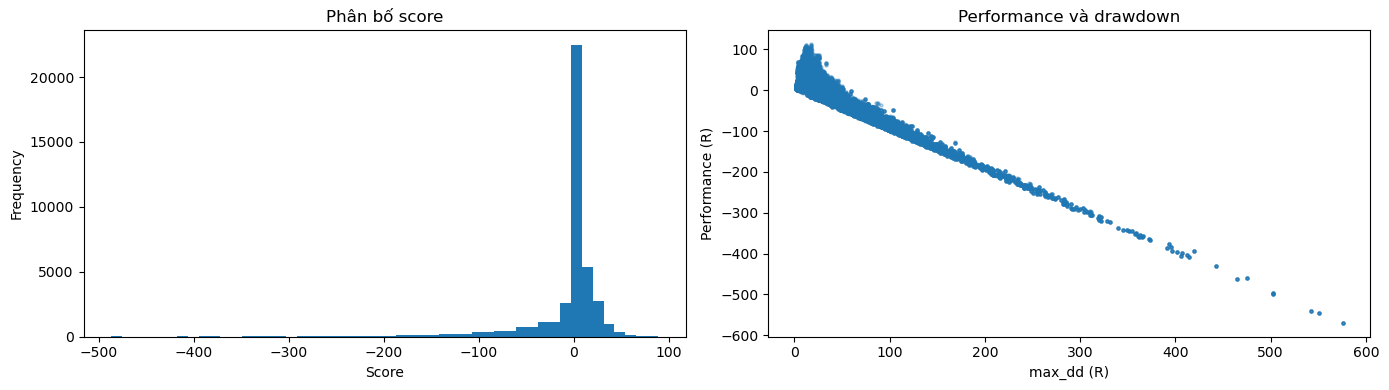

In [24]:
# Biểu đồ: phân bố score và hiệu quả theo drawdown
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()

Trial 41774. Giai đoạn backtest: 2021-01-01 00:00:00 đến 2026-10-14 23:45:00
Tham số: {'boll_window': 200.0, 'boll_window_dev': 2.0, 'rsi_window': 14.0, 'rsi_threshold': 100.0, 'sl_multiplier': 0.5, 'tp_sl_ratio': 1.1, 'max_holding_bars': 288.0, 'band_ratio_max': 0.7}


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,max_holding_bars,band_ratio_max,performance,max_dd,...,min_trades_per_year,number_of_trade,max_concurrent,skipped_entries,number_of_win,win_rate,wilson_p_lower,wilson_fitness,score,score_formula
backtest_trial,200,2.0,14,100,0.5,1.1,288,0.7,68.28582,14.74,...,44.0,324,1,509,195,0.601852,0.545035,0.091339,40.131288,performance*r2**5


,số lệnh
outcome,
take_profit,195
stop,129


Wilson 98%: win rate 60.19%, p_L 54.50%, fitness 0.091 R/lệnh (quan sát 0.211 R/lệnh); timeout/hết dữ liệu 0.0% số lệnh


close_timestamp,2021,2022,2023,2024,2025,2026
số lệnh,44.00,62.00,49.00,68.00,50.00,51.00
R,17.89,27.36,10.11,14.83,6.51,-8.41


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,tp_r,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,1734,2021-01-19 01:30:00,1763,2021-01-19 08:45:00,12.3735,0.759657,13.133157,11.537878,1.1,29,1,stop,-1.0,0.016288,0.001476,-1.017764
1,1801,2021-01-19 18:15:00,1869,2021-01-20 11:15:00,12.2306,0.667927,12.898527,11.495881,1.1,68,1,take_profit,1.1,0.018311,0.003891,1.077798
2,2009,2021-01-21 22:15:00,2031,2021-01-22 03:45:00,11.1329,0.809989,11.942889,10.241913,1.1,22,1,stop,-1.0,0.013745,0.000945,-1.014689
3,2273,2021-01-24 16:15:00,2322,2021-01-25 04:30:00,12.4951,0.409585,12.904685,12.044557,1.1,49,1,stop,-1.0,0.030507,0.004671,-1.035178
4,2384,2021-01-25 20:00:00,2415,2021-01-26 03:45:00,12.2285,0.452473,12.680973,11.730780,1.1,31,1,take_profit,1.1,0.027026,0.002618,1.070356
5,2424,2021-01-26 06:00:00,2476,2021-01-26 19:00:00,11.9211,0.610031,12.531131,11.250065,1.1,52,1,stop,-1.0,0.019542,0.003176,-1.022717
6,4888,2021-02-20 22:00:00,4890,2021-02-20 22:30:00,35.9847,2.943466,38.928166,32.746887,1.1,2,1,take_profit,1.1,0.012225,0.000076,1.087698
7,5564,2021-02-27 23:00:00,5580,2021-02-28 03:00:00,25.2032,1.264649,26.467849,23.812086,1.1,16,1,take_profit,1.1,0.019929,0.000996,1.079075
8,6023,2021-03-04 17:45:00,6049,2021-03-05 00:15:00,25.9160,1.552807,27.468807,24.207912,1.1,26,1,take_profit,1.1,0.016690,0.001356,1.081954
9,6432,2021-03-09 00:00:00,6465,2021-03-09 08:15:00,24.5759,1.522675,26.098575,22.900958,1.1,33,1,stop,-1.0,0.016140,0.001664,-1.017804


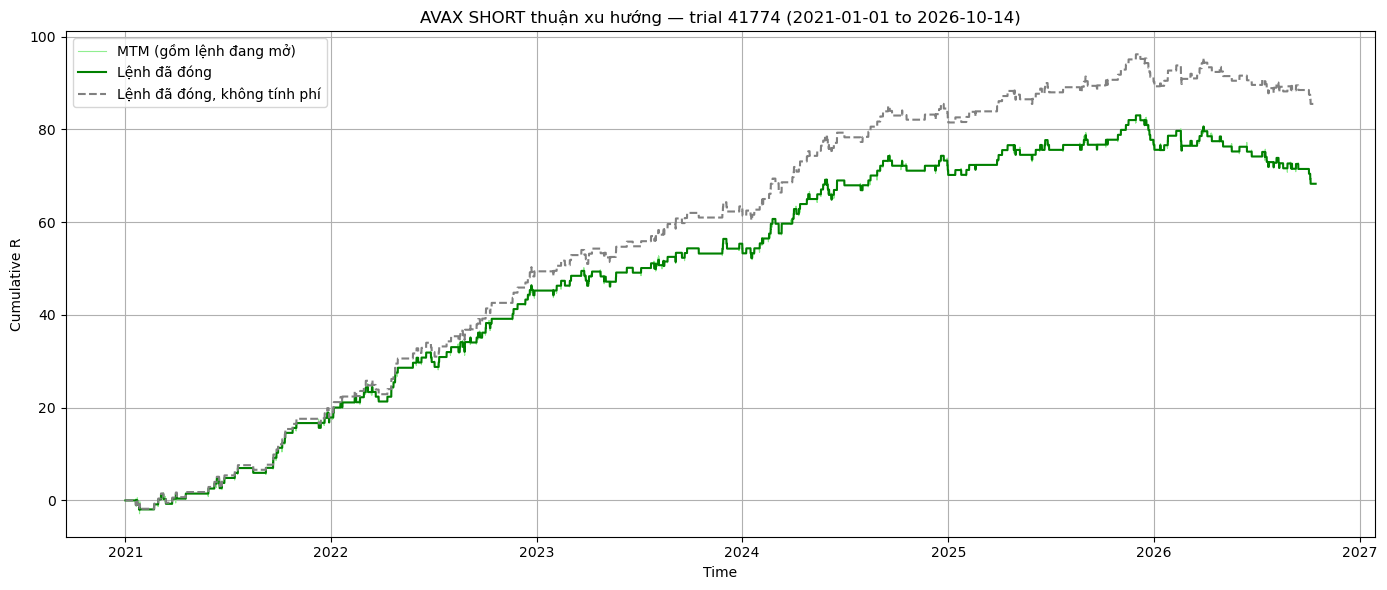

In [27]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
# ID là số thứ tự trong grid: đổi SEARCH_SPACES là ID đổi theo. TRIAL_PARAMS tìm theo tham số (thắng TRIAL_ID);
# tham số không ghi trong TRIAL_PARAMS lấy giá trị mặc định bên dưới.
TRIAL_ID = 41774  # Ví dụ 36240; None = bộ đứng đầu ranked
TRIAL_PARAMS = None  # ví dụ trial 11117 cũ:
#TRIAL_PARAMS = {"boll_window": 100, "boll_window_dev": 2.0, "rsi_window": 5, "rsi_threshold": 15,
#                "sl_multiplier": 1.2, "tp_sl_ratio": 1.1, "max_holding_bars": 288, "band_ratio_max": 0}
BACKTEST_START_DATE = "2021-01-01"  # Ví dụ "2025-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-10-14"    # Ví dụ "2026-01-14"; None = ngày kết thúc train

if TRIAL_PARAMS is not None:
    defaults = {"max_holding_bars": MAX_HOLDING_BARS, "band_ratio_max": 0}
    wanted = {**{k: v for k, v in defaults.items() if k in grid}, **TRIAL_PARAMS}
    match = np.ones(len(grid), dtype=bool)
    for name, value in wanted.items():
        match &= np.isclose(grid[name].to_numpy(dtype=float), float(value))
    if not match.any():
        raise KeyError(f"Không có bộ {wanted} trong grid hiện tại")
    TRIAL_ID = int(np.flatnonzero(match)[0])
if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA)
backtest_result = strategy.score_result(strategy.add_wilson_columns(backtest_result, WILSON_CONFIDENCE),
                                        SCORE_FORMULA)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")

print(f"Trial {TRIAL_ID}. Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
print("Tham số:", params)
display(backtest_trial.to_frame(name="backtest_trial").T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
if not trades.empty:
    # Wilson fitness chỉ là expectancy đầy đủ khi payoff gần nhị phân; timeout làm payoff biến thiên
    print(f"Wilson {WILSON_CONFIDENCE:.0%}: win rate {backtest_trial['win_rate']:.2%}, "
          f"p_L {backtest_trial['wilson_p_lower']:.2%}, fitness {backtest_trial['wilson_fitness']:.3f} R/lệnh "
          f"(quan sát {trades['net_r'].mean():.3f} R/lệnh); timeout/hết dữ liệu "
          f"{trades['outcome'].isin(['timeout', 'end_of_data']).mean():.1%} số lệnh")
    by_year = trades.groupby(trades["close_timestamp"].dt.year)["net_r"].agg(["size", "sum"])
    display(by_year.rename(columns={"size": "số lệnh", "sum": "R"}).round(2).T)
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8, label="MTM (gồm lệnh đang mở)")
    ax.plot(equity["timestamp"], equity["closed_equity"], color="green", label="Lệnh đã đóng")
    # Cùng các lệnh đó nhưng cộng gross_r (bỏ phí vào lệnh và phí giữ lệnh); tín hiệu bị bỏ vì phí > 0.2R vẫn bị bỏ
    gross_steps = np.bincount(trades["exit_index"].to_numpy(dtype=np.int64),
                              weights=trades["gross_r"].to_numpy(dtype=np.float64), minlength=len(equity))
    ax.plot(equity["timestamp"], np.cumsum(gross_steps), color="gray", linestyle="--",
            label="Lệnh đã đóng, không tính phí")
    ax.set(xlabel="Time", ylabel="Cumulative R",
           title=f"AVAX SHORT thuận xu hướng — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()

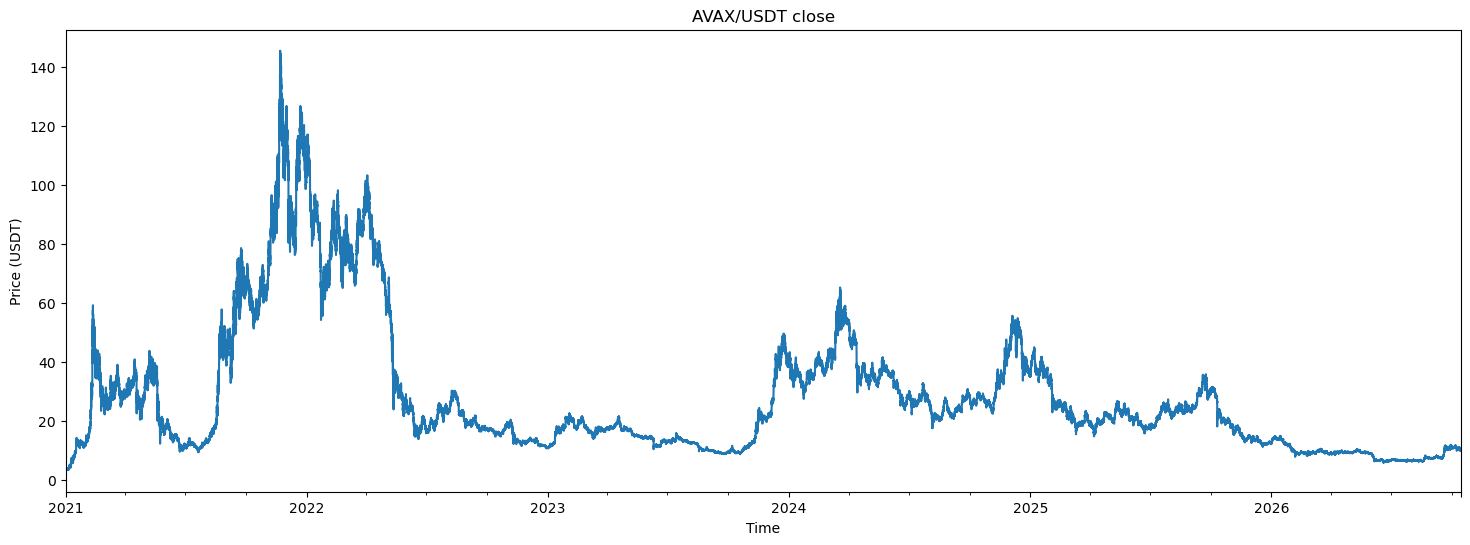

In [26]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()